# Random Forest Regression
Regression is a <b>supervised learning</b> technique used to predict a <b>continuous numerical value</b> based on input features. The goal is to model the relationship between the features and the output.

### Types of Regression:
<b>6) Random Forest Regression:</b>

<b> 6.1) Random Forest Regression (RF)</b> is a supervised machine learning algorithm used in regression problems. It builds multiple decision trees, then averages their predictions to get a more accurate, stable result.


 <b>6.2) How RF works</b>: The algorithm does the following:
 * Choosing m random samples from the dataset
 * Build Decision Trees, based on these randomly selected data
 * Each Tree predicts a value
 * The final prediction is the average of all Tree predictions

#### a - Importing libraries

## Part A - Salary by position level

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### b - Importing Dataset
The HR of a company has collected information from the internet (<b>e.g: glassdoor.com, indeed.com</b>) about salaries for different positions. 

The objective for this company is that, when carrying out interviews and receive <b>salary expectations</b> from the candidate, they want to investigate whether these expectations <b>are reasonable or not</b>, based on <b>Position</b> and <b>Level</b>. Note that the <b>Level</b> can be a continuous value (<b>e.g: 5.5</b>)

The company has hired you as a data scientist and Machine learning specialist to perform the previous task, based on the <b>Random Forest Regression algorithm.</b> 


<b>Note:</b> a random forest averages many trees trained on random samples, which gives more steps and smoother predictions than a single tree.

In [2]:
# importing and displaying dataset 
data = pd.read_csv('../data/Position_Salaries.csv')
data

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [3]:
# Creating Feature vector and output vector
x = data.iloc[:, 1:-1].values
y = data.iloc[:, -1].values
x

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

#### c - Training the RF model on all data

In [4]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=10, random_state=0)
model.fit(x, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of 

#### d - Predicting a new entry
Try predicting, what would be the salary for a Level of 5.5 with RF model <b>'model'</b>

In [5]:
y_pred = model.predict([[5.5]])
y_pred

array([108000.])

#### e- Visualizing the RF results

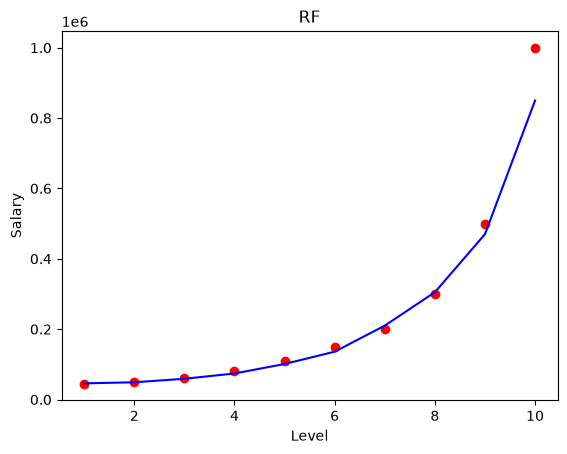

In [6]:
plt.scatter(x, y, color='red')
plt.plot(x, model.predict(x), color='blue')
plt.title('RF')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()

#### f- Visualizing the RF results in higher Resolution

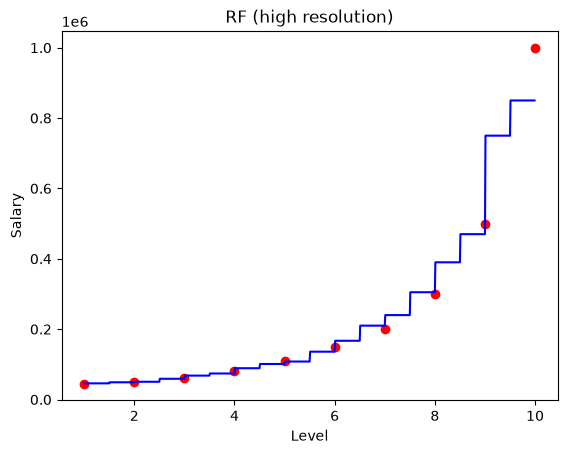

In [7]:
x_grid = np.arange(x.min(), x.max(), 0.01)
x_grid = x_grid.reshape((len(x_grid), 1))
plt.scatter(x, y, color='red')
plt.plot(x_grid, model.predict(x_grid), color='blue')
plt.title('RF (high resolution)')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()

The high-resolution plot shows the model is a step function: every level inside the same interval gets the same prediction.

## Part B - Random Forest Regression on the power plant dataset
The same model on 9,568 readings with 4 features, evaluated on a held-out test set (R²).

In [8]:
dataset = pd.read_csv('../data/Power_Plant.csv')
X = dataset.iloc[:, :-1].values
Y = dataset.iloc[:, -1].values

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [10]:
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1)
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_test)

In [11]:
from sklearn.metrics import r2_score, mean_squared_error
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(-1, 1), np.asarray(y_test).reshape(-1, 1)), 1)[:10])
print('R2  :', round(r2_score(y_test, y_pred), 4))
print('RMSE:', round(float(np.sqrt(mean_squared_error(y_test, y_pred))), 3), 'MW')

[[433.74 431.23]
 [457.6  460.01]
 [463.44 461.14]
 [446.69 445.9 ]
 [459.49 451.29]
 [435.08 432.68]
 [473.52 477.5 ]
 [457.87 459.68]
 [476.1  477.5 ]
 [444.15 444.99]]
R2  : 0.965
RMSE: 3.198 MW
